In [1]:
import pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import bootstrap
import numpy as np
plt.style.use('seaborn-v0_8-whitegrid')

In [2]:
linear11 = pd.read_csv('linear11/results/evaluation.csv')
convex11 = pd.read_csv('convex11/results/evaluation.csv')
concave11 = pd.read_csv('concave11/results/evaluation.csv')
linear21 = pd.read_csv('linear21/results/evaluation.csv')
convex21 = pd.read_csv('convex21/results/evaluation.csv')
concave21 = pd.read_csv('concave21/results/evaluation.csv')
linear31 = pd.read_csv('linear31/results/evaluation.csv')
convex31 = pd.read_csv('convex31/results/evaluation.csv')
concave31 = pd.read_csv('concave31/results/evaluation.csv')
linear41 = pd.read_csv('linear41/results/evaluation.csv')
convex41 = pd.read_csv('convex41/results/evaluation.csv')
concave41 = pd.read_csv('concave41/results/evaluation.csv')
linear51 = pd.read_csv('linear51/results/evaluation.csv')
convex51 = pd.read_csv('convex51/results/evaluation.csv')
concave51 = pd.read_csv('concave51/results/evaluation.csv')

In [3]:
rlinear11 = pd.read_csv('linear11/results/robust_evaluation.csv')
rconvex11 = pd.read_csv('convex11/results/robust_evaluation.csv')
rconcave11 = pd.read_csv('concave11/results/robust_evaluation.csv')
rlinear21 = pd.read_csv('linear21/results/robust_evaluation.csv')
rconvex21 = pd.read_csv('convex21/results/robust_evaluation.csv')
rconcave21 = pd.read_csv('concave21/results/robust_evaluation.csv')
rlinear31 = pd.read_csv('linear31/results/robust_evaluation.csv')
rconvex31 = pd.read_csv('convex31/results/robust_evaluation.csv')
rconcave31 = pd.read_csv('concave31/results/robust_evaluation.csv')
rlinear41 = pd.read_csv('linear41/results/robust_evaluation.csv')
rconvex41 = pd.read_csv('convex41/results/robust_evaluation.csv')
rconcave41 = pd.read_csv('concave41/results/robust_evaluation.csv')
rlinear51 = pd.read_csv('linear51/results/robust_evaluation.csv')
rconvex51 = pd.read_csv('convex51/results/robust_evaluation.csv')
rconcave51 = pd.read_csv('concave51/results/robust_evaluation.csv')

In [4]:
baseline = linear11['Stage 0'].median()

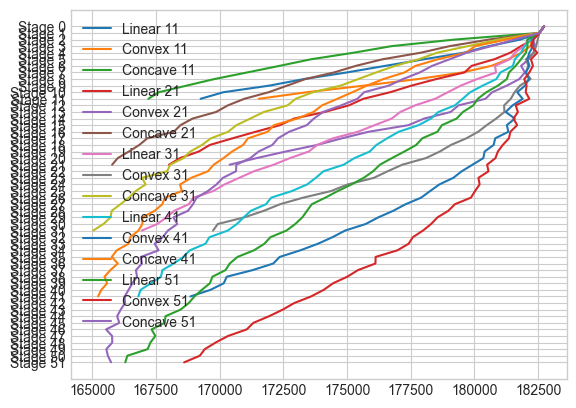

In [5]:
plt.plot(linear11.median().values, linear11.median().index, label='Linear 11')
plt.plot(convex11.median().values, convex11.median().index, label='Convex 11')
plt.plot(concave11.median().values, concave11.median().index, label='Concave 11')

plt.plot(linear21.median().values, linear21.median().index, label='Linear 21')
plt.plot(convex21.median().values, convex21.median().index, label='Convex 21')
plt.plot(concave21.median().values, concave21.median().index, label='Concave 21')

plt.plot(linear31.median().values, linear31.median().index, label='Linear 31')
plt.plot(convex31.median().values, convex31.median().index, label='Convex 31')
plt.plot(concave31.median().values, concave31.median().index, label='Concave 31')

plt.plot(linear41.median().values, linear41.median().index, label='Linear 41')
plt.plot(convex41.median().values, convex41.median().index, label='Convex 41')
plt.plot(concave41.median().values, concave41.median().index, label='Concave 41')

plt.plot(linear51.median().values, linear51.median().index, label='Linear 51')
plt.plot(convex51.median().values, convex51.median().index, label='Convex 51')
plt.plot(concave51.median().values, concave51.median().index, label='Concave 51')

plt.gca().invert_yaxis()
plt.legend()

In [6]:
def get_med_ci(data):
    median = ((baseline - data.median()) / data.median()) * 100
    res = bootstrap(
        (((baseline - data) / data) * 100,), np.median, axis=0, confidence_level=0.95, n_resamples=10000
    )
    ci_low, ci_high = res.confidence_interval
    return median, median - ci_low, ci_high - median

In [7]:
linears = [linear11, linear21, linear31, linear41, linear51]
convexs = [convex11, convex21, convex31, convex41, convex51]
concaves = [concave11, concave21, concave31, concave41, concave51]

rlinears = [rlinear11, rlinear21, rlinear31, rlinear41, rlinear51]
rconvexs = [rconvex11, rconvex21, rconvex31, rconvex41, rconvex51]
rconcaves = [rconcave11, rconcave21, rconcave31, rconcave41, rconcave51]

yerrs_linear = [[], []]
medians_linear = []
for z in linears:
    m, cil, cih = get_med_ci(z[z.columns[-1]])
    medians_linear.append(m)
    yerrs_linear[0].append(cil)
    yerrs_linear[1].append(cih)

yerrs_convex = [[], []]
medians_convex = []
for z in convexs:
    m, cil, cih = get_med_ci(z[z.columns[-1]])
    medians_convex.append(m)
    yerrs_convex[0].append(cil)
    yerrs_convex[1].append(cih)

yerrs_concave = [[], []]
medians_concave = []
for z in concaves:
    m, cil, cih = get_med_ci(z[z.columns[-1]])
    medians_concave.append(m)
    yerrs_concave[0].append(cil)
    yerrs_concave[1].append(cih)

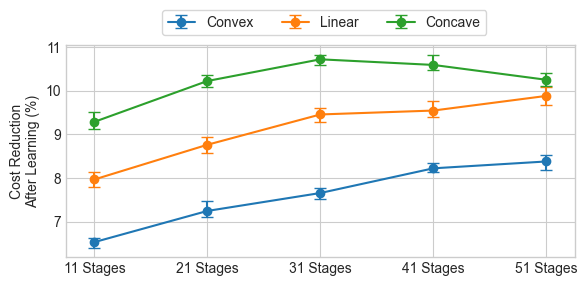

In [8]:
fig, ax = plt.subplots(1, figsize=(6, 3))
ax.errorbar(range(5), medians_convex, yerr=yerrs_convex, fmt="-o", capsize=4, label="Convex")
ax.errorbar(range(5), medians_linear, yerr=yerrs_linear, fmt="-o", capsize=4, label="Linear")
ax.errorbar(range(5), medians_concave, yerr=yerrs_concave, fmt="-o", capsize=4, label="Concave")
# ax.plot([((baseline - v) / baseline) * 100 for v in [c.median().min() for c in convexs]], label='Convex', marker='o')
# ax.plot([((baseline - v) / baseline) * 100 for v in [c.median().min() for c in linears]], label='Linear', marker='o')
# ax.plot([((baseline - v) / baseline) * 100 for v in [c.median().min() for c in concaves]], label='Concave', marker='o')
ax.set_xticks([0, 1, 2, 3, 4])
ax.set_xticklabels(['11 Stages', '21 Stages', '31 Stages', '41 Stages', '51 Stages'])
ax.set_xlim(-0.25, 4.25)
ax.set_ylabel("Cost Reduction\nAfter Learning (%)")
plt.legend(ncol=3, bbox_to_anchor=(0.84, 1.2), frameon=True)
plt.tight_layout()
fig.savefig("../../../plt/annealing_experiment.pdf")

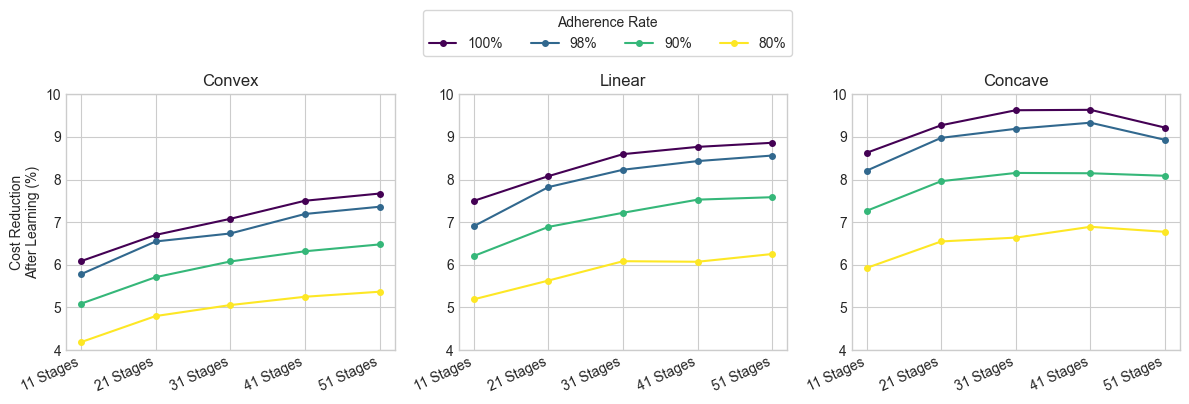

In [9]:
fig, axarr = plt.subplots(1, 3, figsize=(12, 3.5))
cmap = plt.colormaps['viridis']

axarr[0].plot([((baseline - v) / baseline) * 100 for v in [c['Stage 0'].median() for c in rconvexs]], label='100%', marker='o', markersize=4, c=cmap(0.0))
axarr[0].plot([((baseline - v) / baseline) * 100 for v in [c['Stage 4'].median() for c in rconvexs]], label='98%', marker='o', markersize=4, c=cmap(0.333))
axarr[0].plot([((baseline - v) / baseline) * 100 for v in [c['Stage 12'].median() for c in rconvexs]], label='90%', marker='o', markersize=4, c=cmap(0.666))
axarr[0].plot([((baseline - v) / baseline) * 100 for v in [c['Stage 16'].median() for c in rconvexs]], label='80%', marker='o', markersize=4, c=cmap(1.0))
axarr[0].set_ylim(4, 10)
axarr[0].set_title("Convex")
axarr[0].set_xticks([0, 1, 2, 3, 4])
axarr[0].set_xticklabels(['11 Stages', '21 Stages', '31 Stages', '41 Stages', '51 Stages'], rotation=25, ha='right')
axarr[0].set_ylabel("Cost Reduction\nAfter Learning (%)")

axarr[1].plot([((baseline - v) / baseline) * 100 for v in [c['Stage 0'].median() for c in rlinears]], marker='o', markersize=4, c=cmap(0.0))
axarr[1].plot([((baseline - v) / baseline) * 100 for v in [c['Stage 4'].median() for c in rlinears]], marker='o', markersize=4, c=cmap(0.333))
axarr[1].plot([((baseline - v) / baseline) * 100 for v in [c['Stage 12'].median() for c in rlinears]], marker='o', markersize=4, c=cmap(0.666))
axarr[1].plot([((baseline - v) / baseline) * 100 for v in [c['Stage 16'].median() for c in rlinears]], marker='o', markersize=4, c=cmap(1.0))
axarr[1].set_ylim(4, 10)
axarr[1].set_title("Linear")
axarr[1].set_xticks([0, 1, 2, 3, 4])
axarr[1].set_xticklabels(['11 Stages', '21 Stages', '31 Stages', '41 Stages', '51 Stages'], rotation=25, ha='right')

axarr[2].plot([((baseline - v) / baseline) * 100 for v in [c['Stage 0'].median() for c in rconcaves]], marker='o', markersize=4, c=cmap(0.0))
axarr[2].plot([((baseline - v) / baseline) * 100 for v in [c['Stage 4'].median() for c in rconcaves]], marker='o', markersize=4, c=cmap(0.333))
axarr[2].plot([((baseline - v) / baseline) * 100 for v in [c['Stage 12'].median() for c in rconcaves]], marker='o', markersize=4, c=cmap(0.666))
axarr[2].plot([((baseline - v) / baseline) * 100 for v in [c['Stage 16'].median() for c in rconcaves]], marker='o', markersize=4, c=cmap(1.0))
axarr[2].set_ylim(4, 10)
axarr[2].set_title("Concave")
axarr[2].set_xticks([0, 1, 2, 3, 4])
axarr[2].set_xticklabels(['11 Stages', '21 Stages', '31 Stages', '41 Stages', '51 Stages'], rotation=25, ha='right')

fig.legend(ncol=4, bbox_to_anchor=(0.67, 1.16), frameon=True, title="Adherence Rate")
plt.tight_layout()
plt.show()

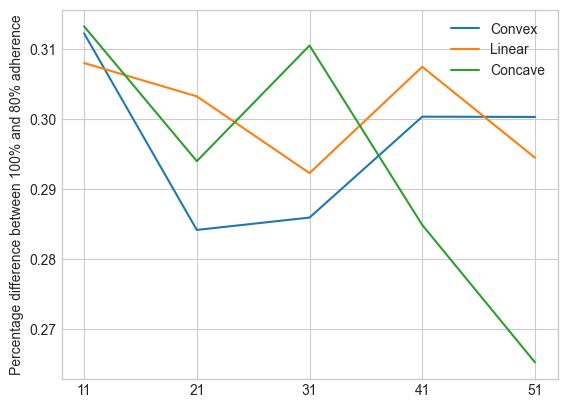

In [10]:
plt.plot([((((baseline - v1) / baseline) * 100) - (((baseline - v2) / baseline) * 100)) / (((baseline - v1) / baseline) * 100) for v1, v2 in zip([c['Stage 0'].median() for c in rconvexs], [c['Stage 16'].median() for c in rconvexs])], label="Convex")
plt.plot([((((baseline - v1) / baseline) * 100) - (((baseline - v2) / baseline) * 100)) / (((baseline - v1) / baseline) * 100) for v1, v2 in zip([c['Stage 0'].median() for c in rlinears], [c['Stage 16'].median() for c in rlinears])], label="Linear")
plt.plot([((((baseline - v1) / baseline) * 100) - (((baseline - v2) / baseline) * 100)) / (((baseline - v1) / baseline) * 100) for v1, v2 in zip([c['Stage 0'].median() for c in rconcaves], [c['Stage 16'].median() for c in rconcaves])], label="Concave")
plt.xticks(range(5), [11, 21, 31, 41, 51])
plt.ylabel("Percentage difference between 100% and 80% adherence")
plt.legend()

In [33]:
p1 = pd.read_csv('p1/results/evaluation.csv')
p32 = pd.read_csv('p32/results/evaluation.csv')
p2 = pd.read_csv('p2/results/evaluation.csv')
p3 = pd.read_csv('p3/results/evaluation.csv')
p4 = pd.read_csv('p4/results/evaluation.csv')
p6 = pd.read_csv('p6/results/evaluation.csv')
p9 = pd.read_csv('p9/results/evaluation.csv')
p15 = pd.read_csv('p15/results/evaluation.csv')
ps = [p1, p32, p2, p3, p4, p6, p9, p15]

In [34]:
yerrs_ps = [[], []]
medians_ps = []
for z in ps:
    m, cil, cih = get_med_ci(z[z.columns[-1]])
    medians_ps.append(m)
    yerrs_ps[0].append(cil)
    yerrs_ps[1].append(cih)

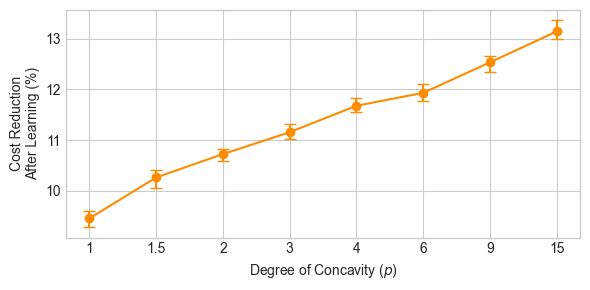

In [36]:
fig, ax = plt.subplots(1, figsize=(6, 3))
ax.errorbar([1, 2, 3, 4, 5, 6, 7, 8], medians_ps, yerr=yerrs_ps, fmt="-o", capsize=4, c='darkorange')
ax.set_xticks([1, 2, 3, 4, 5, 6, 7, 8])
ax.set_xticklabels([1, 1.5, 2, 3, 4, 6, 9, 15])
ax.set_ylabel("Cost Reduction\nAfter Learning (%)")
ax.set_xlabel(r"Degree of Concavity ($p$)")
plt.tight_layout()
# fig.savefig("../../../plt/annealing_experiment.pdf")
plt.show()

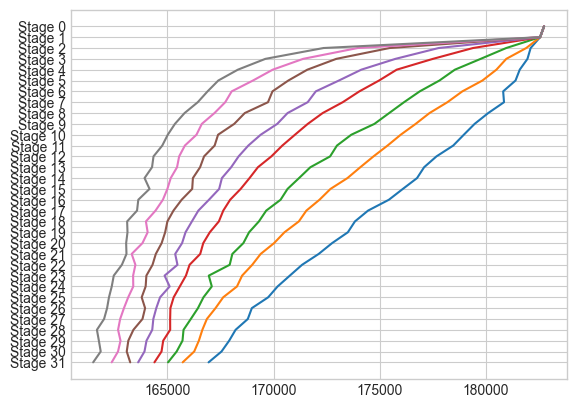

In [37]:
for p in ps:
    plt.plot(p.median().values, p.median().index)
plt.gca().invert_yaxis()